# Table of Contents
1. [Problem Statement and Data Description](#Problem-Statement-and-Data-Description)  
       [Subsections](#Subsections) if needed
2. [Data Preprocessing](#Data-Preprocessing)
3. [Exploratory Data Analysis](#Exploratory-Data-Analysis)
4. [Data splitting](#Data-splitting)
5. [Modeling](#Modeling)
6. [Hyperparameter Tuning](#Hyperparameter-Tuning)
7. [Model Evaluation](#Model-Evaluation)  
       [Model Brief](#Model-Brief) per model, documenting decisions, approach, limitations, etc.
8. [Model Selection and Results](#Model-Selection-and-Results)  
9. [Discussion](#Discussion)
10. [Conclusion](#Conclusion) including ideas beyond the scope of the course (this is stated in the deliverable)

In [1]:
# All imports in this cell per assignment instructions

from IPython.display import display, Markdown

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

In [2]:
# Link to GitHub Repository

display(Markdown("[GitHub Link](https://github.com/miaarnold-png/ads505-final-project)"))

[GitHub Link](https://github.com/miaarnold-png/ads505-final-project)

# Problem Statement and Data Description

Taiwan Global is a fictional financial institution that is looking into the number of clients who default on \
their monthly payments. Customer default is a concern for the bank because it leads to account charge off which\
forces Taiwan Global to absorb the cost of the remaining balance. The more clients who default the more revenue\
the institution loses. They'd like to address customer defaults early on and in house through client outreach\
directed at the clients who are most likely to default on the following month's payment. In order to do so,\
they've brought in a team of data scientists to perform predictive analytics on a sample of 30,000 clients. The\
goal is to create a classification model that accurately predicts customer default and ranks their customers'\
propensities to default on a payment.

### Buisness Objective:

Use early outreach campaigns targeted at customers who are most likely to default on their monthly payments\
to decrease the number of credit card defaults

### Data Mining Goal(s):
- Create a classification model that labels clients as defaulter or non-defaulter.
- Create a classification model that ranks clients by their probability of default

### Success Criteria:

A successful model & campaign when deployed would reduce the overall percent of defaults for the quarter by 1%

### Data and Data Description

The dataset is a xls file that includes 25 attributes and 30,000 instances. It was found on the UCI Repository.\
There is a mix of binary, categorical and numerical variables.There are no missing values but the outcome\
variable is imbalanced.

# Data Preprocessing

In [3]:
df = pd.read_excel(
    "default of credit card clients.xls",
    header=1
)

In [4]:
df.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [5]:
df.shape

(30000, 25)

### 2.1 Initial Data Inspection

The dataset was first examined to understand its dimensions, variable names,
data types, and overall structure before performing data cleaning and
preprocessing.

In [6]:
# Inspect dataset dimensions and column names
print(f"Dataset shape: {df.shape}")

print("\nColumn names:")
print(df.columns.tolist())

df.head()

Dataset shape: (30000, 25)

Column names:
['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'default payment next month']


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [7]:
# Review data types and non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   ID                          30000 non-null  int64
 1   LIMIT_BAL                   30000 non-null  int64
 2   SEX                         30000 non-null  int64
 3   EDUCATION                   30000 non-null  int64
 4   MARRIAGE                    30000 non-null  int64
 5   AGE                         30000 non-null  int64
 6   PAY_0                       30000 non-null  int64
 7   PAY_2                       30000 non-null  int64
 8   PAY_3                       30000 non-null  int64
 9   PAY_4                       30000 non-null  int64
 10  PAY_5                       30000 non-null  int64
 11  PAY_6                       30000 non-null  int64
 12  BILL_AMT1                   30000 non-null  int64
 13  BILL_AMT2                   30000 non-null  int64
 14  BILL_AMT3        

In [8]:
df = df.rename(
    columns={"default payment next month": "DEFAULT"}
)

print(df.columns.tolist())

['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'DEFAULT']


### 2.2 Missing Values

Missing values were evaluated across all variables to determine whether
imputation or removal would be required before modeling.

In [9]:
# Check missing values in each column
missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing_Count": missing_values,
    "Missing_Percent": (missing_values / len(df)) * 100
})

missing_summary

,Missing_Count,Missing_Percent
ID,0,0.0
LIMIT_BAL,0,0.0
SEX,0,0.0
EDUCATION,0,0.0
MARRIAGE,0,0.0
AGE,0,0.0
PAY_0,0,0.0
PAY_2,0,0.0
PAY_3,0,0.0
PAY_4,0,0.0


In [10]:
print(
    "Total missing values:",
    df.isnull().sum().sum()
)

Total missing values: 0


### 2.3 Duplicate and Identifier Check

Duplicate observations and customer identifiers were examined to prevent
redundant records or non-predictive identifiers from affecting the models.

In [11]:
# Check for duplicate rows
duplicate_count = df.duplicated().sum()

print(f"Number of duplicate rows: {duplicate_count}")

Number of duplicate rows: 0


In [12]:
# Check whether ID uniquely identifies each observation
print(f"Number of observations: {len(df)}")
print(f"Number of unique IDs: {df['ID'].nunique()}")

Number of observations: 30000
Number of unique IDs: 30000


In [13]:
# Remove customer identifier because it is not a predictive feature
df = df.drop(columns=["ID"])

print(f"Dataset shape after removing ID: {df.shape}")

Dataset shape after removing ID: (30000, 24)


### 2.4 Categorical Variable Validation

Categorical variables were reviewed to verify that their observed values were
consistent with the categories documented in the dataset description. Particular
attention was given to demographic variables because undocumented category
codes may require recoding before modeling.

In [14]:
# Review categorical variable values
categorical_cols = [
    "SEX",
    "EDUCATION",
    "MARRIAGE"
]

for col in categorical_cols:
    print(f"\n{col}:")
    print(df[col].value_counts().sort_index())


SEX:
SEX
1    11888
2    18112
Name: count, dtype: int64

EDUCATION:
EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64

MARRIAGE:
MARRIAGE
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64


In [15]:
# Consolidate undocumented categorical codes into "Other"
df["EDUCATION"] = df["EDUCATION"].replace({
    0: 4,
    5: 4,
    6: 4
})

df["MARRIAGE"] = df["MARRIAGE"].replace({
    0: 3
})

In [16]:
# Verify cleaned categorical values
for col in ["SEX", "EDUCATION", "MARRIAGE"]:
    print(f"\n{col}:")
    print(df[col].value_counts().sort_index())


SEX:
SEX
1    11888
2    18112
Name: count, dtype: int64

EDUCATION:
EDUCATION
1    10585
2    14030
3     4917
4      468
Name: count, dtype: int64

MARRIAGE:
MARRIAGE
1    13659
2    15964
3      377
Name: count, dtype: int64


In [17]:
# Review repayment status values
pay_status_cols = [
    "PAY_0",
    "PAY_2",
    "PAY_3",
    "PAY_4",
    "PAY_5",
    "PAY_6"
]

for col in pay_status_cols:
    print(f"\n{col}:")
    print(df[col].value_counts().sort_index())


PAY_0:
PAY_0
-2     2759
-1     5686
 0    14737
 1     3688
 2     2667
 3      322
 4       76
 5       26
 6       11
 7        9
 8       19
Name: count, dtype: int64

PAY_2:
PAY_2
-2     3782
-1     6050
 0    15730
 1       28
 2     3927
 3      326
 4       99
 5       25
 6       12
 7       20
 8        1
Name: count, dtype: int64

PAY_3:
PAY_3
-2     4085
-1     5938
 0    15764
 1        4
 2     3819
 3      240
 4       76
 5       21
 6       23
 7       27
 8        3
Name: count, dtype: int64

PAY_4:
PAY_4
-2     4348
-1     5687
 0    16455
 1        2
 2     3159
 3      180
 4       69
 5       35
 6        5
 7       58
 8        2
Name: count, dtype: int64

PAY_5:
PAY_5
-2     4546
-1     5539
 0    16947
 2     2626
 3      178
 4       84
 5       17
 6        4
 7       58
 8        1
Name: count, dtype: int64

PAY_6:
PAY_6
-2     4895
-1     5740
 0    16286
 2     2766
 3      184
 4       49
 5       13
 6       19
 7       46
 8        2
Name: count, dtype

**Repayment Status Review:** The repayment-history variables contained the
expected delinquency codes as well as values of -2 and 0, which are not fully
defined in the supplied variable documentation. Because these values occur
frequently and may represent meaningful payment states, they were retained
during initial cleaning rather than being removed or arbitrarily recoded.
Their treatment will be considered during model-specific preprocessing.

### 2.5 Outlier Assessment

Potential outliers were examined for the continuous financial and demographic
variables. Because unusually large credit limits, bill balances, and payment
amounts may represent legitimate customer behavior, the purpose of this step
was to identify extreme observations rather than automatically remove them.

In [18]:
# Continuous variables considered for outlier assessment
numeric_cols = [
    "LIMIT_BAL",
    "AGE",
    "BILL_AMT1",
    "BILL_AMT2",
    "BILL_AMT3",
    "BILL_AMT4",
    "BILL_AMT5",
    "BILL_AMT6",
    "PAY_AMT1",
    "PAY_AMT2",
    "PAY_AMT3",
    "PAY_AMT4",
    "PAY_AMT5",
    "PAY_AMT6"
]

outlier_summary = []

for col in numeric_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_count = (
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ).sum()

    outlier_summary.append({
        "Variable": col,
        "Outlier_Count": outlier_count,
        "Outlier_Percent": round(
            outlier_count / len(df) * 100,
            2
        )
    })

outlier_summary = pd.DataFrame(outlier_summary)

outlier_summary

,Variable,Outlier_Count,Outlier_Percent
0,LIMIT_BAL,167,0.56
1,AGE,272,0.91
2,BILL_AMT1,2400,8.00
3,BILL_AMT2,2395,7.98
4,BILL_AMT3,2469,8.23
5,BILL_AMT4,2622,8.74
6,BILL_AMT5,2725,9.08
7,BILL_AMT6,2693,8.98
8,PAY_AMT1,2745,9.15
9,PAY_AMT2,2714,9.05


**Interpretation:** The IQR method identified relatively few potential
outliers in `LIMIT_BAL` and `AGE`, while approximately 8–10% of observations
were flagged in the monthly bill and payment amount variables. These financial
variables are expected to have skewed distributions because customers can have
substantially different credit balances and payment amounts.

The identified observations were therefore treated as potential extreme values
rather than automatic data errors. No observations were removed solely based
on the IQR criterion because doing so could eliminate legitimate high-value
customers and distort the underlying credit-risk patterns. Extreme values were
retained for modeling, with scaling or transformation to be considered later
within model-specific preprocessing pipelines.

In [19]:
# Review ranges of continuous variables for plausibility
range_summary = df[numeric_cols].agg(
    ["min", "median", "max"]
).T

range_summary

,min,median,max
LIMIT_BAL,10000.0,140000.0,1000000.0
AGE,21.0,34.0,79.0
BILL_AMT1,-165580.0,22381.5,964511.0
BILL_AMT2,-69777.0,21200.0,983931.0
BILL_AMT3,-157264.0,20088.5,1664089.0
BILL_AMT4,-170000.0,19052.0,891586.0
BILL_AMT5,-81334.0,18104.5,927171.0
BILL_AMT6,-339603.0,17071.0,961664.0
PAY_AMT1,0.0,2100.0,873552.0
PAY_AMT2,0.0,2009.0,1684259.0


### 2.6 Correlated Features

Correlations among continuous predictors were examined to identify potential
multicollinearity. This is particularly important for the six monthly bill
amount variables because measurements from consecutive months may contain
overlapping information.

In [20]:
# Calculate correlations among continuous predictors
correlation_matrix = df[numeric_cols].corr()

correlation_matrix.round(2)

,LIMIT_BAL,AGE,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6
LIMIT_BAL,1.00,0.14,0.29,0.28,0.28,0.29,0.30,0.29,0.20,0.18,0.21,0.20,0.22,0.22
AGE,0.14,1.00,0.06,0.05,0.05,0.05,0.05,0.05,0.03,0.02,0.03,0.02,0.02,0.02
BILL_AMT1,0.29,0.06,1.00,0.95,0.89,0.86,0.83,0.80,0.14,0.10,0.16,0.16,0.17,0.18
BILL_AMT2,0.28,0.05,0.95,1.00,0.93,0.89,0.86,0.83,0.28,0.10,0.15,0.15,0.16,0.17
BILL_AMT3,0.28,0.05,0.89,0.93,1.00,0.92,0.88,0.85,0.24,0.32,0.13,0.14,0.18,0.18
BILL_AMT4,0.29,0.05,0.86,0.89,0.92,1.00,0.94,0.90,0.23,0.21,0.30,0.13,0.16,0.18
BILL_AMT5,0.30,0.05,0.83,0.86,0.88,0.94,1.00,0.95,0.22,0.18,0.25,0.29,0.14,0.16
BILL_AMT6,0.29,0.05,0.80,0.83,0.85,0.90,0.95,1.00,0.20,0.17,0.23,0.25,0.31,0.12
PAY_AMT1,0.20,0.03,0.14,0.28,0.24,0.23,0.22,0.20,1.00,0.29,0.25,0.20,0.15,0.19
PAY_AMT2,0.18,0.02,0.10,0.10,0.32,0.21,0.18,0.17,0.29,1.00,0.24,0.18,0.18,0.16


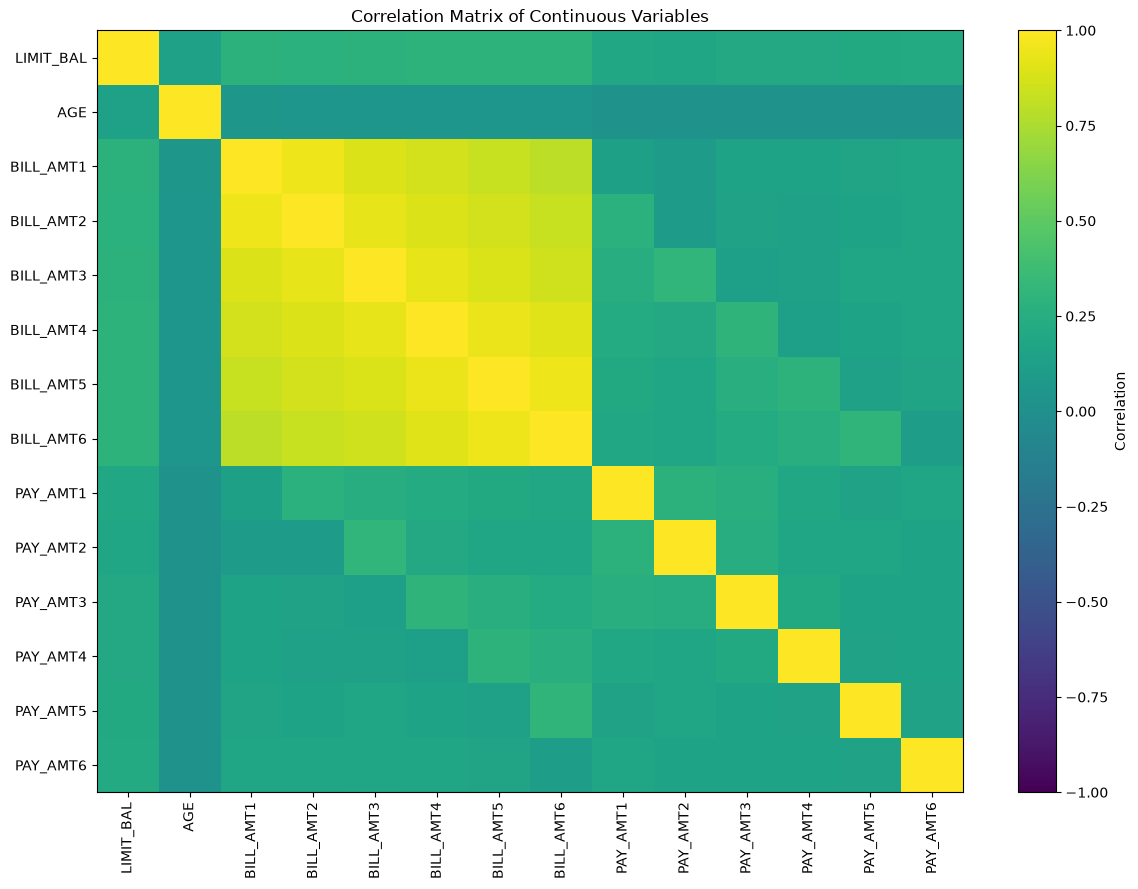

In [21]:
plt.figure(figsize=(12, 9))

plt.imshow(
    correlation_matrix,
    aspect="auto",
    vmin=-1,
    vmax=1
)

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(numeric_cols)),
    numeric_cols,
    rotation=90
)

plt.yticks(
    range(len(numeric_cols)),
    numeric_cols
)

plt.title("Correlation Matrix of Continuous Variables")
plt.tight_layout()
plt.show()

**Interpretation:** The correlation analysis revealed substantial
multicollinearity among the six monthly bill amount variables. Correlations
between several `BILL_AMT` variables exceeded 0.80, with adjacent months
showing particularly strong relationships of approximately 0.90 or greater.
This is expected because these variables represent repeated monthly balances
for the same customers.

In contrast, the payment amount variables, age, and credit limit generally
showed low to moderate correlations with the other continuous predictors.
Because the project will evaluate both linear and tree-based models, the highly
correlated bill variables were retained in the cleaned master dataset rather
than automatically removed. Their impact will be evaluated during
model-specific preprocessing, since multicollinearity is more relevant for
models such as logistic regression and LDA than for tree-based methods such as
decision trees and random forests.

In [22]:
# Identify highly correlated feature pairs
high_corr_pairs = []

for i in range(len(correlation_matrix.columns)):
    for j in range(i):
        corr_value = correlation_matrix.iloc[i, j]

        if abs(corr_value) >= 0.80:
            high_corr_pairs.append({
                "Variable_1": correlation_matrix.columns[i],
                "Variable_2": correlation_matrix.columns[j],
                "Correlation": round(corr_value, 3)
            })

high_corr_df = pd.DataFrame(high_corr_pairs)

high_corr_df.sort_values(
    by="Correlation",
    ascending=False
).reset_index(drop=True)

,Variable_1,Variable_2,Correlation
0,BILL_AMT2,BILL_AMT1,0.951
1,BILL_AMT6,BILL_AMT5,0.946
2,BILL_AMT5,BILL_AMT4,0.940
3,BILL_AMT3,BILL_AMT2,0.928
4,BILL_AMT4,BILL_AMT3,0.924
5,BILL_AMT6,BILL_AMT4,0.901
6,BILL_AMT3,BILL_AMT1,0.892
7,BILL_AMT4,BILL_AMT2,0.892
8,BILL_AMT5,BILL_AMT3,0.884
9,BILL_AMT5,BILL_AMT2,0.860


### 2.7 Data Preprocessing Summary

The preprocessing assessment identified no missing observations or duplicate
records. The customer `ID` variable was removed because it served only as a
unique identifier. Undocumented values in `EDUCATION` and `MARRIAGE` were
consolidated into their existing "Other" categories, while ambiguous repayment
status codes were retained to avoid making unsupported assumptions about their
meaning.

Potential outliers were identified using the IQR method. Because extreme
financial values may represent legitimate customer behavior, no observations
were removed solely for being statistical outliers. Correlation analysis
identified substantial multicollinearity among the monthly bill amount
variables; however, these variables were retained in the cleaned master dataset
so that their treatment can be evaluated within the appropriate modeling
pipelines.

The resulting dataset is therefore cleaned while preserving potentially useful
credit-risk information for subsequent data splitting and model development.

In [23]:
# Create cleaned master dataset for subsequent analysis
df_clean = df.copy()

print(f"Final cleaned dataset shape: {df_clean.shape}")
print(f"Total missing values: {df_clean.isnull().sum().sum()}")

Final cleaned dataset shape: (30000, 24)
Total missing values: 0


### Transition to Feature-Engineered Dataset

Following the initial cleaning and preprocessing steps, the cleaned dataset
was used for feature engineering. The engineered dataset used for modeling
contains additional credit-utilization and credit-limit features, including
`UTIL_AVG`, `UTIL_MAX`, `UTIL_RECENT`, `UTIL_CHANGE`, `LIMIT_BAND`, and
`HIGH_UTIL_MONTHS`.

The resulting `credit_default_engineered.csv` dataset contains 30,000
observations and 41 variables and is used in the subsequent data-splitting
and modeling sections.

In [24]:
df_engineered = pd.read_csv("credit_default_engineered.csv")

print("Engineered dataset shape:", df_engineered.shape)

print("\nEDUCATION values:")
print(df_engineered["EDUCATION"].value_counts().sort_index())

print(
    "\nHIGH_UTIL_MONTHS present:",
    "HIGH_UTIL_MONTHS" in df_engineered.columns
)

Engineered dataset shape: (30000, 41)

EDUCATION values:
EDUCATION
1    10585
2    14030
3     4917
4      468
Name: count, dtype: int64

HIGH_UTIL_MONTHS present: True


There is now a total of 41 features after feature engineering.

# Exploratory Data Analysis

# Data Splitting

In [25]:
# Final predictor set without demographic variables

base_predictors = [
    "LIMIT_BAL",
    "EDUCATION",
    "PAY_0",
    "PAY_2",
    "PAY_3",
    "PAY_4",
    "PAY_5",
    "PAY_6",
    "BILL_AMT1",
    "BILL_AMT2",
    "BILL_AMT3",
    "BILL_AMT4",
    "BILL_AMT5",
    "BILL_AMT6",
    "PAY_AMT1",
    "PAY_AMT2",
    "PAY_AMT3",
    "PAY_AMT4",
    "PAY_AMT5",
    "PAY_AMT6",
    "UTIL_AVG",
    "UTIL_MAX",
    "UTIL_RECENT",
    "UTIL_CHANGE",
    "LIMIT_BAND",
    "HIGH_UTIL_MONTHS"
]

df_model = df_engineered[
    base_predictors + ["DEFAULT"]
].copy()

print("Modeling dataset shape:", df_model.shape)

Modeling dataset shape: (30000, 27)


In [26]:
# Stratified 60/20/20 train-validation-test split

target = df_model["DEFAULT"]

train_idx, temp_idx = train_test_split(
    df_model.index,
    test_size=0.40,
    random_state=42,
    stratify=target
)

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=42,
    stratify=target.loc[temp_idx]
)

print("Training observations:", len(train_idx))
print("Validation observations:", len(val_idx))
print("Test observations:", len(test_idx))

Training observations: 18000
Validation observations: 6000
Test observations: 6000


In [27]:
# Create training, validation, and final test datasets

train = df_model.loc[train_idx]
val = df_model.loc[val_idx]
test = df_model.loc[test_idx]

X_train = train.drop(columns=["DEFAULT"])
y_train = train["DEFAULT"]

X_val = val.drop(columns=["DEFAULT"])
y_val = val["DEFAULT"]

X_test = test.drop(columns=["DEFAULT"])
y_test = test["DEFAULT"]

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

X_train: (18000, 26)
X_val: (6000, 26)
X_test: (6000, 26)


In [28]:
# Verify that stratification preserved the class distribution

print(
    "Overall default rate:",
    round(df_model["DEFAULT"].mean(), 4)
)

print(
    "Training default rate:",
    round(y_train.mean(), 4)
)

print(
    "Validation default rate:",
    round(y_val.mean(), 4)
)

print(
    "Test default rate:",
    round(y_test.mean(), 4)
)

Overall default rate: 0.2212
Training default rate: 0.2212
Validation default rate: 0.2212
Test default rate: 0.2212


**Split Verification:** The dataset was divided into 60% training,
20% validation, and 20% final test sets using stratified sampling.
The default rate remained approximately 22.12% in each subset,
confirming that the class distribution was preserved. The final
test set remained untouched during model development and model
selection.

# Modeling

## Model Building Strategy

Multiple classification algorithms were evaluated during model
development, including Logistic Regression, Linear Discriminant
Analysis, Decision Tree, Random Forest, and AdaBoost.

The final model comparison focused on versions that excluded the
agreed demographic predictors. F1-score was used as the primary
hyperparameter-tuning metric because the business objective requires
balancing the identification of customers who are likely to default
with the need to avoid unnecessary intervention with customers who
are unlikely to default.

Precision, recall, ROC-AUC, and PR-AUC were retained as supporting
metrics for model evaluation.

In [29]:
# Reusable preprocessing function

def build_preprocessor(X, scale_numeric=True):
    """Create preprocessing for numeric and categorical predictors."""

    # Numerically stored variables that are conceptually categorical
    coded_categorical = [
        "SEX",
        "EDUCATION",
        "MARRIAGE"
    ]

    # Keep only variables actually present in the current dataset
    coded_categorical = [
        col for col in coded_categorical
        if col in X.columns
    ]

    # Detect text/category variables such as LIMIT_BAND
    detected_categorical = X.select_dtypes(
        include=["object", "category", "string"]
    ).columns.tolist()

    categorical_cols = list(
        dict.fromkeys(
            coded_categorical + detected_categorical
        )
    )

    numeric_cols = [
        col for col in X.columns
        if col not in categorical_cols
    ]

    transformers = []

    if numeric_cols:
        numeric_transformer = (
            StandardScaler()
            if scale_numeric
            else "passthrough"
        )

        transformers.append(
            (
                "numeric",
                numeric_transformer,
                numeric_cols
            )
        )

    if categorical_cols:
        transformers.append(
            (
                "categorical",
                OneHotEncoder(
                    handle_unknown="ignore",
                    drop="first"
                ),
                categorical_cols
            )
        )

    return ColumnTransformer(
        transformers=transformers,
        remainder="drop"
    )

In [30]:
# Logistic Regression pipeline without demographic predictors

log_preprocessor = build_preprocessor(
    X_train,
    scale_numeric=True
)

log_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            log_preprocessor
        ),
        (
            "model",
            LogisticRegression(
                max_iter=2000,
                random_state=42
            )
        )
    ]
)

print("Logistic Regression pipeline created.")

Logistic Regression pipeline created.


# Hyperparameter Tuning

In [31]:
# Logistic Regression hyperparameter grid

log_param_grid = {
    "model__C": [0.01, 0.1, 1, 10],
    "model__class_weight": [None, "balanced"]
}

cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [32]:
# Tune Logistic Regression using F1-score

log_grid = GridSearchCV(
    estimator=log_pipeline,
    param_grid=log_param_grid,
    scoring="f1",
    cv=cv_strategy,
    n_jobs=-1,
    refit=True
)

log_grid.fit(
    X_train,
    y_train
)

print("Best parameters:")
print(log_grid.best_params_)

print(
    "Best cross-validation F1:",
    round(log_grid.best_score_, 3)
)

Best parameters:
{'model__C': 0.01, 'model__class_weight': 'balanced'}
Best cross-validation F1: 0.493


# Model Evaluation

In [33]:
# Reusable classification evaluation function

def evaluate_classifier(
    model_name,
    y_true,
    y_pred,
    y_prob
):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(
            y_true,
            y_pred
        ),
        "Precision": precision_score(
            y_true,
            y_pred,
            zero_division=0
        ),
        "Recall": recall_score(
            y_true,
            y_pred,
            zero_division=0
        ),
        "F1": f1_score(
            y_true,
            y_pred,
            zero_division=0
        ),
        "ROC_AUC": roc_auc_score(
            y_true,
            y_prob
        ),
        "PR_AUC": average_precision_score(
            y_true,
            y_prob
        )
    }

In [34]:
# Evaluate tuned Logistic Regression on validation data

best_log_model = log_grid.best_estimator_

log_val_pred = best_log_model.predict(
    X_val
)

log_val_prob = best_log_model.predict_proba(
    X_val
)[:, 1]

log_val_result = evaluate_classifier(
    "Tuned Logistic Regression",
    y_val,
    log_val_pred,
    log_val_prob
)

pd.DataFrame(
    [log_val_result]
).round(3)

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Tuned Logistic Regression,0.703,0.391,0.613,0.477,0.711,0.474


In [35]:
# Validation confusion matrix

print(
    confusion_matrix(
        y_val,
        log_val_pred
    )
)

[[3404 1269]
 [ 513  814]]


In [36]:
# Validation results from the completed model-development notebook

model_comparison = pd.DataFrame([
    {
        "Model": "Random Forest",
        "Accuracy": 0.780,
        "Precision": 0.503,
        "Recall": 0.565,
        "F1": 0.532,
        "ROC_AUC": 0.775,
        "PR_AUC": 0.536
    },
    {
        "Model": "AdaBoost",
        "Accuracy": 0.783,
        "Precision": 0.510,
        "Recall": 0.500,
        "F1": 0.505,
        "ROC_AUC": 0.682,
        "PR_AUC": 0.365
    },
    {
        "Model": "Decision Tree",
        "Accuracy": 0.750,
        "Precision": 0.448,
        "Recall": 0.568,
        "F1": 0.501,
        "ROC_AUC": 0.748,
        "PR_AUC": 0.485
    },
    {
        "Model": "LDA",
        "Accuracy": 0.728,
        "Precision": 0.419,
        "Recall": 0.592,
        "F1": 0.491,
        "ROC_AUC": 0.704,
        "PR_AUC": 0.471
    },
    {
        "Model": "Logistic Regression",
        "Accuracy": 0.703,
        "Precision": 0.391,
        "Recall": 0.613,
        "F1": 0.477,
        "ROC_AUC": 0.711,
        "PR_AUC": 0.474
    }
])

model_comparison.sort_values(
    "F1",
    ascending=False
).reset_index(drop=True)

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Random Forest,0.780,0.503,0.565,0.532,0.775,0.536
1,AdaBoost,0.783,0.510,0.500,0.505,0.682,0.365
2,Decision Tree,0.750,0.448,0.568,0.501,0.748,0.485
3,LDA,0.728,0.419,0.592,0.491,0.704,0.471
4,Logistic Regression,0.703,0.391,0.613,0.477,0.711,0.474


### Training vs. Validation Generalization Check

Because Random Forest achieved the highest validation F1-score, training and
validation F1-scores were compared with Logistic Regression to assess model
generalization and potential overfitting.

In [37]:
generalization_comparison = pd.DataFrame({
    "Model": [
        "Random Forest",
        "Logistic Regression"
    ],
    "Training_F1": [
        0.671,
        0.495
    ],
    "Validation_F1": [
        0.532,
        0.477
    ]
})

generalization_comparison["F1_Gap"] = (
    generalization_comparison["Training_F1"]
    - generalization_comparison["Validation_F1"]
)

generalization_comparison.round(3)

,Model,Training_F1,Validation_F1,F1_Gap
0,Random Forest,0.671,0.532,0.139
1,Logistic Regression,0.495,0.477,0.018


## Model Brief

### Logistic Regression

**Decision and Purpose:**  
Logistic Regression was evaluated as an interpretable baseline and final
candidate model for predicting next-month credit-card default. The model was
selected for final testing because it showed strong recall and relatively
stable performance between the training and validation datasets.

**Approach:**  
The model was implemented using a scikit-learn Pipeline. Numeric predictors
were standardized using `StandardScaler`, while categorical predictors were
one-hot encoded. Hyperparameters were tuned using 5-fold stratified
cross-validation with F1-score as the optimization metric.

The final Logistic Regression model used:

- `C = 0.01`
- `class_weight = "balanced"`

The balanced class weighting was used to help address the imbalance between
default and non-default customers.

**Validation Performance:**  
The tuned model achieved:

- Accuracy: 0.703
- Precision: 0.391
- Recall: 0.613
- F1-score: 0.477
- ROC-AUC: 0.711
- PR-AUC: 0.474

Although Random Forest achieved a higher validation F1-score, Logistic
Regression showed a much smaller training-to-validation F1 gap, indicating
more stable generalization. It also achieved the highest validation recall
among the candidate models using the agreed demographic exclusions.

**Strengths:**  
Logistic Regression is relatively interpretable, computationally efficient,
and produces predicted probabilities that can be used to rank customers by
default risk. Its higher recall is useful for identifying customers who may
benefit from proactive intervention.

**Limitations:**  
The model produced relatively low precision, meaning that some customers
flagged as high-risk would not actually default. Logistic Regression also
assumes a relatively simple relationship between predictors and the log-odds
of default. In addition, probability calibration was not evaluated, so the
predicted probabilities are better interpreted as risk-ranking scores unless
calibration is assessed.

**Recommended Use:**  
The model can be used to prioritize customers for tiered outreach based on
predicted default risk. The final classification threshold and intervention
strategy should be determined using actual business costs, outreach capacity,
and the relative cost of false positives and false negatives.

# Model Selection and Results

Random Forest produced the highest validation F1-score among the
candidate models. However, comparison of training and validation
performance showed a substantially larger generalization gap for
Random Forest than for Logistic Regression.

Random Forest decreased from a training F1-score of approximately
0.671 to a validation F1-score of 0.532. Logistic Regression was
considerably more stable, decreasing from approximately 0.495 on
training data to 0.477 on validation data.

Logistic Regression also achieved the highest validation recall
among the non-demographic candidate models at approximately 0.613.
Because the business objective emphasizes identifying customers who
may default early enough to support proactive intervention, model
stability and recall were important considerations in addition to
F1-score.

The team therefore selected Logistic Regression as the final model.
The model also produces estimated default probabilities, allowing
customers to be ranked by risk and supporting tiered outreach or
intervention strategies.

In [38]:
# Final evaluation on the untouched test set

final_test_pred = best_log_model.predict(
    X_test
)

final_test_prob = best_log_model.predict_proba(
    X_test
)[:, 1]

final_test_result = evaluate_classifier(
    "Final Logistic Regression - Test",
    y_test,
    final_test_pred,
    final_test_prob
)

pd.DataFrame(
    [final_test_result]
).round(3)

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Final Logistic Regression - Test,0.715,0.407,0.632,0.495,0.728,0.506


In [39]:
# Final test-set confusion matrix

final_test_cm = confusion_matrix(
    y_test,
    final_test_pred
)

print("Final Test Confusion Matrix:")
print(final_test_cm)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        final_test_pred,
        digits=3
    )
)

Final Test Confusion Matrix:
[[3451 1222]
 [ 488  839]]

Classification Report:
              precision    recall  f1-score   support

           0      0.876     0.738     0.801      4673
           1      0.407     0.632     0.495      1327

    accuracy                          0.715      6000
   macro avg      0.642     0.685     0.648      6000
weighted avg      0.772     0.715     0.734      6000



In [40]:
# Rank test-set customers by predicted probability of default

default_predictions = pd.DataFrame({
    "Actual_Default": y_test.to_numpy(),
    "Predicted_Default": final_test_pred,
    "Default_Probability": final_test_prob
})

default_predictions = (
    default_predictions
    .sort_values(
        "Default_Probability",
        ascending=False
    )
    .reset_index(drop=True)
)

default_predictions.head(20)

,Actual_Default,Predicted_Default,Default_Probability
0,1,1,0.997323
1,0,1,0.996753
2,1,1,0.995948
3,1,1,0.995739
4,1,1,0.989859
5,0,1,0.985418
6,0,1,0.979310
7,1,1,0.978938
8,1,1,0.974158
9,0,1,0.972701


In [41]:
# Calculate cumulative gains

ranked_predictions = default_predictions.copy()

ranked_predictions["Rank"] = (
    np.arange(len(ranked_predictions)) + 1
)

ranked_predictions["Population_Pct"] = (
    ranked_predictions["Rank"]
    / len(ranked_predictions)
)

ranked_predictions["Cumulative_Defaults"] = (
    ranked_predictions[
        "Actual_Default"
    ].cumsum()
)

total_defaults = (
    ranked_predictions[
        "Actual_Default"
    ].sum()
)

ranked_predictions["Cumulative_Gain"] = (
    ranked_predictions[
        "Cumulative_Defaults"
    ]
    / total_defaults
)

ranked_predictions[
    [
        "Population_Pct",
        "Cumulative_Gain"
    ]
].head()

,Population_Pct,Cumulative_Gain
0,0.000167,0.000754
1,0.000333,0.000754
2,0.000500,0.001507
3,0.000667,0.002261
4,0.000833,0.003014


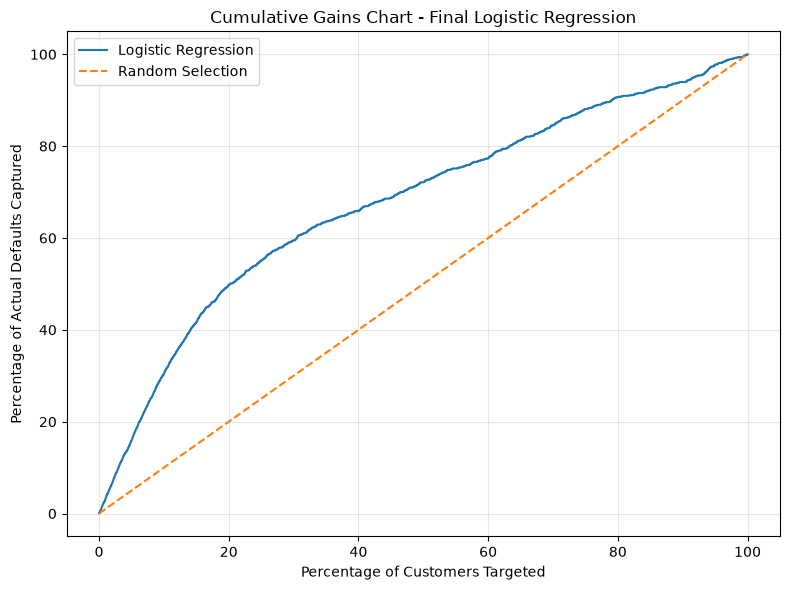

In [42]:
# Cumulative gains chart

plt.figure(figsize=(8, 6))

plt.plot(
    ranked_predictions["Population_Pct"] * 100,
    ranked_predictions["Cumulative_Gain"] * 100,
    label="Logistic Regression"
)

plt.plot(
    [0, 100],
    [0, 100],
    linestyle="--",
    label="Random Selection"
)

plt.xlabel("Percentage of Customers Targeted")
plt.ylabel("Percentage of Actual Defaults Captured")
plt.title(
    "Cumulative Gains Chart - Final Logistic Regression"
)
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [43]:
# How many defaults are captured by targeting the highest-risk customers?

for target_pct in [0.10, 0.20, 0.30]:
    cutoff = int(
        len(ranked_predictions)
        * target_pct
    )

    captured = (
        ranked_predictions
        .iloc[:cutoff][
            "Actual_Default"
        ]
        .sum()
    )

    captured_pct = (
        captured
        / total_defaults
    )

    print(
        f"Top {int(target_pct * 100)}% of customers "
        f"capture {captured_pct:.1%} of actual defaults."
    )

Top 10% of customers capture 30.4% of actual defaults.
Top 20% of customers capture 49.7% of actual defaults.
Top 30% of customers capture 59.5% of actual defaults.


In [44]:
# Lift by customer-risk decile

ranked_predictions["Decile"] = pd.qcut(
    ranked_predictions["Rank"],
    q=10,
    labels=range(1, 11)
)

overall_default_rate = (
    ranked_predictions[
        "Actual_Default"
    ].mean()
)

lift_table = (
    ranked_predictions
    .groupby(
        "Decile",
        observed=False
    )
    .agg(
        Customers=(
            "Actual_Default",
            "size"
        ),
        Defaults=(
            "Actual_Default",
            "sum"
        ),
        Average_Probability=(
            "Default_Probability",
            "mean"
        )
    )
    .reset_index()
)

lift_table["Default_Rate"] = (
    lift_table["Defaults"]
    / lift_table["Customers"]
)

lift_table["Lift"] = (
    lift_table["Default_Rate"]
    / overall_default_rate
)

lift_table.round(3)

,Decile,Customers,Defaults,Average_Probability,Default_Rate,Lift
0,1,600,403,0.808,0.672,3.037
1,2,600,257,0.645,0.428,1.937
2,3,600,129,0.549,0.215,0.972
3,4,600,85,0.498,0.142,0.641
4,5,600,83,0.461,0.138,0.625
5,6,600,69,0.425,0.115,0.520
6,7,600,96,0.383,0.160,0.723
7,8,600,81,0.337,0.135,0.610
8,9,600,44,0.276,0.073,0.332
9,10,600,80,0.165,0.133,0.603


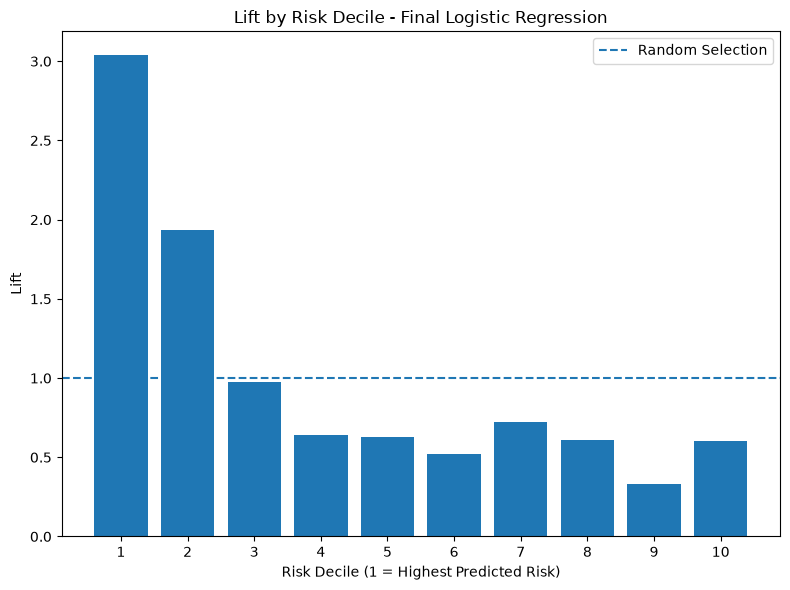

In [45]:
# Lift chart

plt.figure(figsize=(8, 6))

plt.bar(
    lift_table[
        "Decile"
    ].astype(str),
    lift_table["Lift"]
)

plt.axhline(
    y=1,
    linestyle="--",
    label="Random Selection"
)

plt.xlabel(
    "Risk Decile (1 = Highest Predicted Risk)"
)
plt.ylabel("Lift")
plt.title(
    "Lift by Risk Decile - Final Logistic Regression"
)

plt.legend()
plt.tight_layout()
plt.show()

# Discussion

## Model Performance and Business Impact

The final tuned Logistic Regression model was evaluated once on the
previously untouched test set. The model achieved an accuracy of 0.715,
precision of 0.407, recall of 0.632, F1-score of 0.495, ROC-AUC of 0.728,
and PR-AUC of 0.506.

The model identified 839 of the 1,327 customers who actually defaulted,
corresponding to a recall of approximately 63.2%.Although precision was lower at 40.7%, this tradeoff may be acceptable for an
early-intervention use case if the cost of missing a genuinely at-risk customer
is greater than the cost of additional outreach. The appropriate tradeoff
should ultimately be evaluated using actual intervention costs and outreach
capacity.

The predicted default scores also provide meaningful customer
prioritization. Targeting only the highest-risk 10% of customers captured
approximately 30.4% of actual defaults. Expanding outreach to the
highest-risk 20% captured approximately 49.7% of defaults, while targeting
the highest-risk 30% captured approximately 59.5%.

The highest-risk decile achieved a lift of approximately 3.04, meaning
customers in this group defaulted at roughly three times the overall
population rate. This demonstrates that the model can help Taiwan Global
concentrate intervention resources on customers with substantially elevated
default risk rather than applying the same outreach strategy to all customers.

A tiered intervention strategy could therefore be used. Customers with the
highest predicted risk could receive higher-priority or more personalized
outreach, while customers with moderate risk could receive lower-cost
interventions such as reminders or educational communications.

The operating probability threshold should ultimately depend on outreach
capacity and the relative business costs of false positives and false
negatives. In addition, probability calibration should be evaluated before
the predicted probabilities are interpreted as absolute default-risk
estimates rather than primarily as ranking scores.

The project's business success criterion of reducing the quarterly default rate
by 1% cannot be verified from historical classification performance alone.
That outcome would need to be evaluated after deployment through a controlled
pilot or similar intervention study.

# Conclusion

The project developed and compared multiple classification models
for predicting next-month credit-card default. Final model
selection considered predictive performance, generalization,
recall, interpretability, and the ability to produce customer-level
default probabilities.

Logistic Regression was selected as the final model because it
demonstrated relatively stable training-to-validation performance,
strong recall, and interpretable probability estimates that can
support targeted early-intervention strategies.

On the untouched test set, the final Logistic Regression model achieved a
recall of 0.632 and an F1-score of 0.495. The ranking analysis showed that the
highest-risk 10% of customers contained approximately 30.4% of observed
defaults, while the highest-risk 20% contained approximately 49.7%. The
highest-risk decile achieved a lift of approximately 3.04 relative to random
selection, demonstrating that the model can meaningfully prioritize customers
for targeted outreach.

Future work could evaluate probability calibration, alternative
decision thresholds, intervention-specific cost functions, model
performance on newer customer populations, and ongoing monitoring
for model drift. The effectiveness of the proposed outreach
strategy should ultimately be evaluated through controlled
deployment and measurement of actual reductions in customer
defaults.